Quelle: https://github.com/teddykoker/grokking

# Grokking: Das Phänomen der verzögerten Generalisierung

Dieses Notebook demonstriert das faszinierende Phänomen **Grokking** in der Künstlichen Intelligenz. 
Grokking beschreibt den Moment, in dem ein neuronales Netzwerk eine Aufgabe nach sehr langem Training 
plötzlich logisch *begreift* (generalisiert), anstatt die Daten nur auswendig zu lernen (Overfitting).

## Was passiert beim Grokking?
1. **Phase 1 - Auswendiglernen (Overfitting):** Das Modell erzielt schnell 100% Genauigkeit auf den Trainingsdaten, versagt aber völlig bei neuen Testdaten.
2. **Phase 2 - Die Stagnation:** Über viele Epochen hinweg verbessert sich das Modell scheinbar überhaupt nicht mehr.
3. **Phase 3 - Der Aha-Moment (Grokking):** Plötzlich springt die Genauigkeit auf den Testdaten schlagartig auf fast 100% hoch. Das Modell hat die zugrundeliegende mathematische Regel gelernt.

---

<div style="display: flex; justify-content: space-between;">
    <img src="acc.png" alt="Bild 1" style="width: 48%;">
    <img src="loss.png" alt="Bild 2" style="width: 48%;">
</div>


Dieses Notebook untersucht das Grokking-Phänomen. Grokking tritt auf, wenn ein Modell lange nach dem Erreichen von 100% Trainings-Genauigkeit plötzlich lernt, auf ungesehene Daten zu generalisieren.

## Das Experiment: Modulare Division
Wir trainieren einen Transformer auf die Operation: x mal y modulo 97.
- Training: 50% der Kombinationen.
- Validierung: Die restlichen 50%.
- Ziel: Beobachtung des plötzlichen Anstiegs der Validierungs-Genauigkeit.

## 1. Vorbereitung und Bibliotheken laden
Wir nutzen **PyTorch** für das neuronale Netzwerk und **Matplotlib** für die spätere Visualisierung.

In [1]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from IPython.display import clear_output
from sklearn.metrics import confusion_matrix
import numpy as np

## Architektur
Ein klassischer Decoder-only Transformer. Die L2-Norm der Gewichte wird im Training überwacht, da ein Sinken der Norm oft dem Grokking vorausgeht.

# Erklärung der Transformer-Decoder-Architektur

Dieser Code implementiert einen standardmäßigen **kausalen Transformer-Decoder** in PyTorch. Diese Architektur bildet das Fundament moderner autoregressiver Sprachmodelle (wie z. B. GPT). Sie besteht aus zwei Hauptklassen: `Block` (eine einzelne Transformer-Schicht) und `Decoder` (das gesamte Netzwerk).

---

## 1. Die Klasse `Block` (Transformer-Schicht)

Die Klasse `Block` repräsentiert eine einzelne Schicht des Transformers. Sie kombiniert Mechanismen zur Informationsverarbeitung (Attention) und Feature-Transformation (MLP).

### Struktur (`__init__`)
* **`self.ln_1` & `self.ln_2`**: `nn.LayerNorm` stabilisiert das Training durch Normalisierung der Aktivierungen entlang der Feature-Dimension ($dim$).
* **`self.attn`**: `nn.MultiheadAttention` erlaubt es dem Modell, sich auf verschiedene Teile der Eingabesequenz gleichzeitig zu fokussieren.
* **`self.mlp`**: Ein zweischichtiges Feed-Forward-Netzwerk (Multilayer Perceptron). Es projiziert die Daten zuerst in einen höherdimensionalen Raum ($dim \rightarrow dim \times 4$), wendet die nichtlineare Aktivierungsfunktion **GELU** an und projiziert sie wieder zurück ($dim \times 4 \rightarrow dim$).

### Datenfluss (`forward`)
1. **Kausale Maskierung (`mask`)**: 
   $$mask_{ij} = \begin{cases} 0 & \text{wenn } i \geq j \\ -\infty & \text{wenn } i < j \end{cases}$$
   Es wird eine obere Dreiecksmatrix erzeugt, die mit $-\infty$ gefüllt ist (ausgenommen die Diagonale). Dies verhindert, dass ein Token in die "Zukunft" schauen kann (wichtig für die Textgenerierung).
2. **Pre-Layer-Norm**: Die Normalisierung (`ln_1`) wird *vor* der Attention angewendet (modernes Pre-LN-Design).
3. **Multi-Head Attention**: Berechnet die gewichteten Beziehungen der Token zueinander. Die Maske wird über `attn_mask=mask` übergeben.
4. **Erste Residualverbindung**: Das Ergebnis der Attention wird zur ursprünglichen Eingabe addiert (`x = x + a`).
5. **Zweite Residualverbindung & MLP**: Das normalisierte `x` passiert das MLP und wird erneut zum vorherigen Zustand addiert (`x = x + self.mlp(self.ln_2(x))`).

---

## 2. Die Klasse `Decoder` (Gesamtnetzwerk)

Die Klasse `Decoder` verbindet die Ein- und Ausgänge und stapelt mehrere `Block`-Schichten hintereinander.

### Struktur (`__init__`)
* **`self.t_emb`**: `nn.Embedding` (Token Embedding) wandelt diskrete Token-IDs (Wörter/Subwörter) in kontinuierliche Vektoren der Dimension $dim$ um.
* **`self.p_emb`**: `nn.Embedding` (Positional Embedding) lernt Vektoren für jede Position in der Sequenz, da der Attention-Mechanismus selbst keine Reihenfolge erkennt.
* **`self.layers`**: Eine Liste (`nn.ModuleList`), die die definierte Anzahl an `Block`-Schichten (Standard: 2) speichert.
* **`self.ln_f`**: Die finale Layer-Norm zur Stabilisierung vor der Vorhersage.
* **`self.head`**: Eine lineare Schicht, die den finalen Vektor wieder auf die Größe des Vokabulars (`tokens=99`) projiziert, um Wahrscheinlichkeiten für das nächste Token zu berechnen.

### Datenfluss (`forward`)
1. **Positions-Indizes**: Erstellt einen Vektor `pos` von $0$ bis `seq_l - 1`.
2. **Embedding-Fusion**: Holt die Token- und Positions-Embeddings und addiert sie (`h = self.t_emb(x) + self.p_emb(pos)`).
3. **Schicht-Verarbeitung**: Die kombinierten Embeddings durchlaufen sequenziell alle `Block`-Schichten in einer Schleife.
4. **Ausgabe-Projektion**: Wendet die finale Normalisierung an und berechnet über die lineare Schicht `self.head` die Logits für die nächste Token-Vorhersage.


In [2]:
class Block(nn.Module):
    def __init__(self, dim, num_heads):
        super().__init__()
        self.ln_1 = nn.LayerNorm(dim)
        self.ln_2 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, num_heads)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * 4),
            nn.GELU(),
            nn.Linear(dim * 4, dim)
        )

    def forward(self, x):
        sz = x.shape[0]
        mask = torch.triu(torch.full((sz, sz), float('-inf'), device=x.device), diagonal=1)
        n = self.ln_1(x)
        a, _ = self.attn(n, n, n, attn_mask=mask, need_weights=False)
        x = x + a
        x = x + self.mlp(self.ln_2(x))
        return x

class Decoder(nn.Module):
    def __init__(self, dim=128, layers=2, heads=4, tokens=99, seq_len=5):
        super().__init__()
        self.t_emb = nn.Embedding(tokens, dim)
        self.p_emb = nn.Embedding(seq_len, dim)
        self.layers = nn.ModuleList([Block(dim, heads) for _ in range(layers)])
        self.ln_f = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, tokens, bias=False)

    def forward(self, x):
        seq_l = x.shape[0]
        pos = torch.arange(seq_l, device=x.device).unsqueeze(-1)
        h = self.t_emb(x) + self.p_emb(pos)
        for layer in self.layers:
            h = layer(h)
        return self.head(self.ln_f(h))

# Visualisieren wir das  

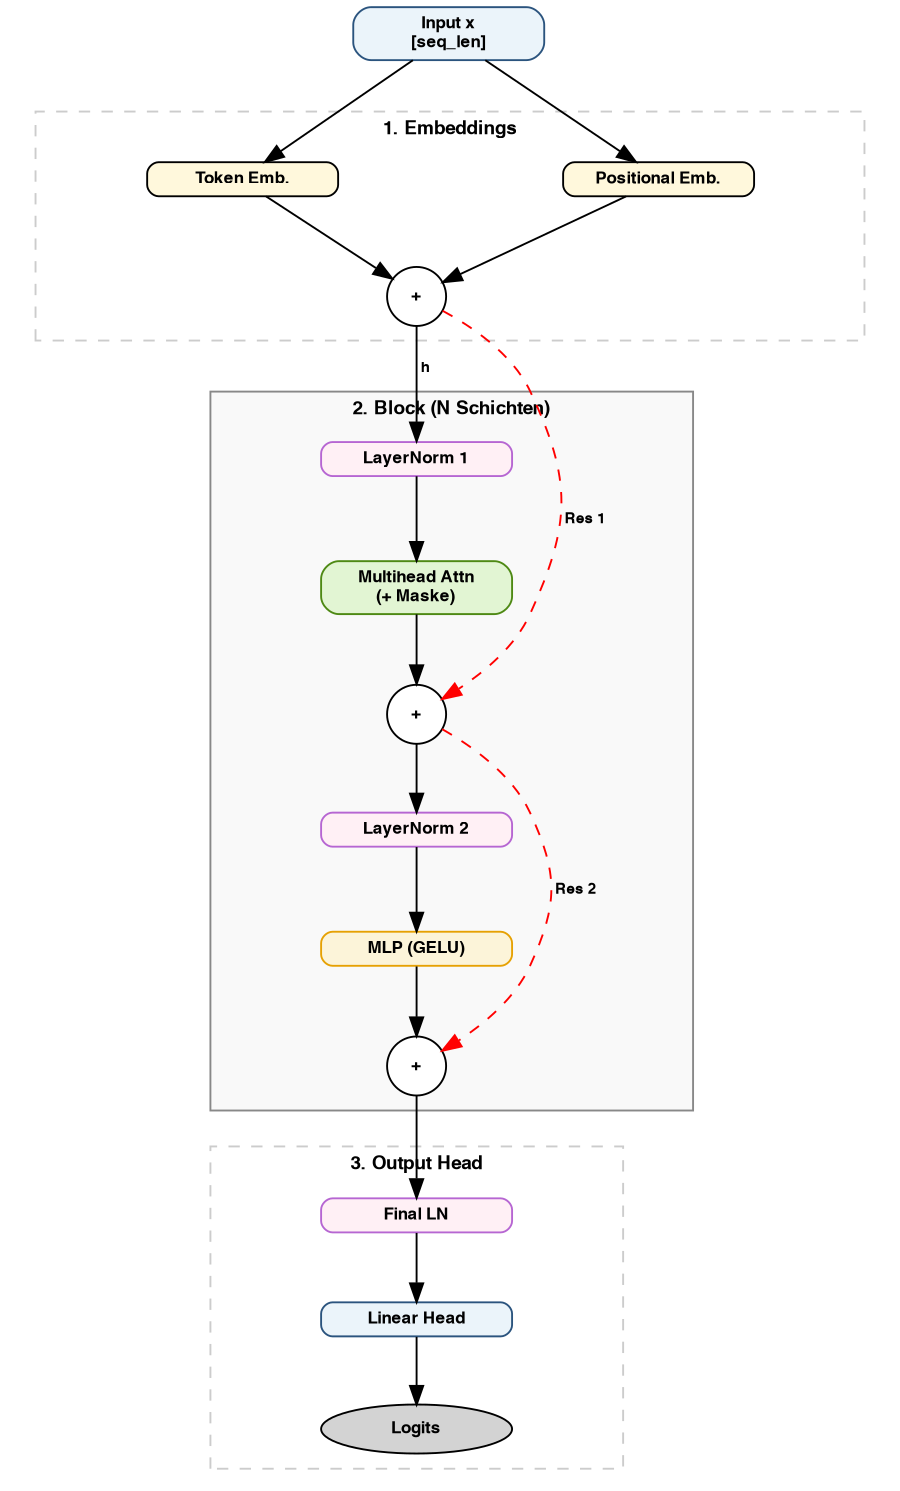

In [3]:
from graphviz import Digraph
from IPython.display import Image, display

# Kompaktes, vertikales Layout (TB = Top to Bottom)
dot = Digraph(comment='Transformer Decoder Architektur', format='png')
dot.attr(rankdir='TB', size='6,10!', ratio='fill', dpi='150')
dot.attr('node', fontname='Helvetica', fontsize='9', shape='box', style='filled, rounded', height='0.25', width='1.4')
dot.attr('edge', fontname='Helvetica', fontsize='8')

# --- INPUT ---
dot.node('input', 'Input x\n[seq_len]', fillcolor='#EBF4FA', color='#2B547E')

# --- 1. EMBEDDINGS ---
with dot.subgraph(name='cluster_emb') as c:
    c.attr(label='1. Embeddings', fontname='Helvetica-Bold', fontsize='10', color='#CCCCCC', style='dashed')
    c.node('t_emb', 'Token Emb.', fillcolor='#FFF8DC')
    c.node('p_emb', 'Positional Emb.', fillcolor='#FFF8DC')
    c.node('add_emb', '+', fillcolor='#FFFFFF', shape='circle', width='0.3', height='0.3')

dot.edge('input', 't_emb')
dot.edge('input', 'p_emb')
dot.edge('t_emb', 'add_emb')
dot.edge('p_emb', 'add_emb')

# --- 2. TRANSFORMER BLOCK ---
with dot.subgraph(name='cluster_block') as b:
    b.attr(label='2. Block (N Schichten)', fontname='Helvetica-Bold', fontsize='10', color='#888888', style='filled', fillcolor='#F9F9F9')
    b.node('ln1', 'LayerNorm 1', fillcolor='#FFF0F5', color='#B666D2')
    b.node('attn', 'Multihead Attn\n(+ Maske)', fillcolor='#E2F5D3', color='#4E8914')
    b.node('res1', '+', fillcolor='#FFFFFF', shape='circle', width='0.3', height='0.3')
    b.node('ln2', 'LayerNorm 2', fillcolor='#FFF0F5', color='#B666D2')
    b.node('mlp', 'MLP (GELU)', fillcolor='#FCF4D9', color='#E6A103')
    b.node('res2', '+', fillcolor='#FFFFFF', shape='circle', width='0.3', height='0.3')

dot.edge('add_emb', 'ln1', label=' h')
dot.edge('ln1', 'attn')
dot.edge('attn', 'res1')

# Rote, gestrichelte Linien für die Residual-Bypässe
dot.edge('add_emb', 'res1', color='#FF0000', style='dashed', constraint='false', label=' Res 1')

dot.edge('res1', 'ln2')
dot.edge('ln2', 'mlp')
dot.edge('mlp', 'res2')
dot.edge('res1', 'res2', color='#FF0000', style='dashed', constraint='false', label=' Res 2')

# --- 3. OUTPUT HEAD ---
with dot.subgraph(name='cluster_out') as o:
    o.attr(label='3. Output Head', fontname='Helvetica-Bold', fontsize='10', color='#CCCCCC', style='dashed')
    o.node('ln_f', 'Final LN', fillcolor='#FFF0F5', color='#B666D2')
    o.node('head', 'Linear Head', fillcolor='#EBF4FA', color='#2B547E')
    o.node('output', 'Logits', fillcolor='#D3D3D3', shape='ellipse')

dot.edge('res2', 'ln_f')
dot.edge('ln_f', 'head')
dot.edge('head', 'output')

# Bild erzeugen und im Notebook ausgeben
display(Image(dot.pipe()))


## 2. Die Aufgabe: Modulo-Addition ($x * y \pmod p$)
Grokking lässt sich am besten an algorithmischen Aufgaben wie der Modulo-Arithmetik zeigen.
Wir wählen eine Primzahl $p = 97$. Es gibt insgesamt $97 \times 97 $ mögliche Kombinationen.
Wir teilen diese in **Trainingsdaten** (50%) und **Testdaten** (50%) auf.

(Häufig wird auch 19 verwenden)

In [4]:
def get_data(p):
    x = torch.arange(p)
    y = torch.arange(1, p)
    x, y = torch.cartesian_prod(x, y).T
    op, eq = p + 1, p
    res = (x * y) % p
    return torch.stack([x, torch.full_like(x, op), y, torch.full_like(x, eq), res])

p = 97
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = Decoder(tokens=p+2).to(device)
data = get_data(p)
indices = torch.randperm(data.shape[1])
split = data.shape[1] // 2
train_d = data[:, indices[:split]].to(device)
val_d = data[:, indices[split:]].to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1.0)
history = {'t_acc': [], 'v_acc': [], 'l2': []}

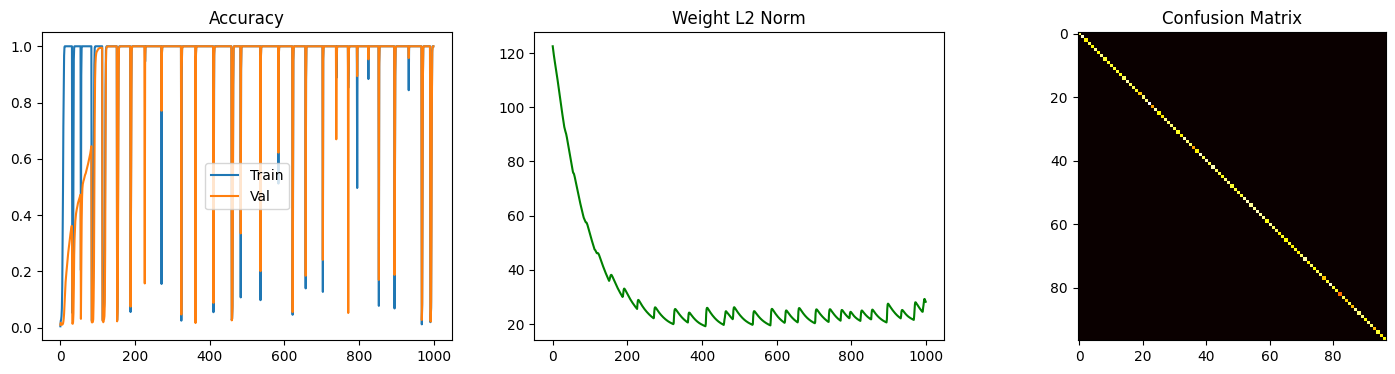

Grokking complete!


In [5]:
for epoch in tqdm(range(10*1000)):
    model.train()
    logits = model(train_d[:-1])
    loss = F.cross_entropy(logits[-1], train_d[-1])
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    if epoch % 10 == 0:
        model.eval()
        with torch.no_grad():
            v_logits = model(val_d[:-1])
            v_acc = (v_logits[-1].argmax(-1) == val_d[-1]).float().mean().item()
            t_acc = (logits[-1].argmax(-1) == train_d[-1]).float().mean().item()
            l2 = sum(p.pow(2).sum() for p in model.parameters()).sqrt().item()
            
            history['t_acc'].append(t_acc)
            history['v_acc'].append(v_acc)
            history['l2'].append(l2)

            clear_output(wait=True)
            fig, ax = plt.subplots(1, 3, figsize=(18, 4))
            ax[0].plot(history['t_acc'], label='Train')
            ax[0].plot(history['v_acc'], label='Val')
            ax[0].set_title('Accuracy')
            ax[0].legend()
            
            ax[1].plot(history['l2'], color='green')
            ax[1].set_title('Weight L2 Norm')
            
            preds = v_logits[-1].argmax(-1).cpu().numpy()
            cm = confusion_matrix(val_d[-1].cpu().numpy(), preds, labels=range(p))
            ax[2].imshow(cm, cmap='hot')
            ax[2].set_title('Confusion Matrix')
            plt.show()
            
            if v_acc > 0.98: 
                print('Grokking complete!')
               # break

<div style="display: flex; justify-content: space-between;">
    <img src="grokking-pattern.png" alt="Bild 1" style="width: 48%;">
    <img src="grokking-frequencies.gif" alt="Bild 2" style="width: 48%;">
</div>


## Fazit
- **Langes Training lohnt sich:** Ein Modell, das bei Validierungsdaten stagniert, ist nicht zwingend am Ende seiner Fähigkeiten. 
- **Die Rolle der Regularisierung:** Durch Mechanismen wie `weight_decay` (Gewichtsabnahme) räumt der Optimierer im Hintergrund ungenutzte mathematische "Pfade" auf, bis nur noch die eleganteste und universellste Logik übrig bleibt.